# 03 - Fine-tuning `indonesian-nlp/wav2vec2-indonesian-javanese-sundanese`

**IF4071 Fase II - ASR bahasa Sunda dengan wav2vec 2.0 + CTC.**

## A. Tujuan dan gambaran eksperimen
Notebook ini melanjutkan pelatihan checkpoint wav2vec 2.0 yang sudah berupa model ASR (Indonesia, Jawa, Sunda) dengan korpus bahasa Sunda kelompok kami, sehingga model beradaptasi ke penutur, kondisi rekaman, dan ujaran spontan (kata pengisi, alih kode) pada korpus ini.

**Arsitektur.** Encoder CNN mengubah gelombang 16 kHz menjadi satu vektor per ±20 ms, encoder Transformer menambahkan konteks, dan kepala linear memberi distribusi atas karakter dan token *blank* pada tiap frame. **Loss CTC** menjumlahkan semua perataan frame-ke-karakter yang valid sehingga tidak diperlukan penyelarasan manual. Dekode memakai **greedy CTC**: argmax per frame, gabungkan ulangan, buang *blank*.

**Alur:**
1. Muat data (pembagian per penutur) dan periksa tokenizer.
2. Ukur baseline zero-shot (model tanpa fine-tuning).
3. Uji 4 nilai learning rate (5 epoch tiap nilai), pilih yang ber-WER validasi terendah.
4. Latih penuh dengan learning rate terpilih (maksimal 50 epoch, *early stopping* pada WER validasi).
5. Evaluasi validasi dan analisis kesalahan, lalu evaluasi data uji **satu kali**.
6. Demo transkripsi.

**Aturan:** konfigurasi, pembagian data, seed, dan prosedur sama dengan notebook 02 (Cahya) agar dapat dibandingkan. Satu-satunya perbedaan terletak pada checkpoint. Model dipilih hanya dari validasi (epoch ber-WER validasi terendah). Audio dan transkripsi uji hanya dipakai pada bagian L. Sebelumnya hanya daftar penutur uji yang diperiksa agar tidak tumpang tindih.

## B. Lingkungan
Kaggle: **Accelerator GPU T4 (x2)** dan **Internet On** (untuk mengunduh checkpoint).

In [1]:
SEED = 42
DATASET_ROOT = None
OUTPUT_ROOT = "/kaggle/working/asr_outputs"
USE_ALL_GPUS = True

import gc
import importlib.util
import inspect
import json
import os
import platform
import random
import shutil
import subprocess
import sys
import time
from collections import Counter
from dataclasses import dataclass
from importlib.metadata import version
from pathlib import Path

if not USE_ALL_GPUS:
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

missing = [p for p in ("jiwer", "accelerate", "soundfile") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Terpasang:", missing, "- bila impor gagal, pilih Run > Restart session lalu jalankan ulang.")

import jiwer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import transformers
from huggingface_hub import model_info
from IPython.display import Audio, display
from scipy.signal import resample_poly
from transformers import EarlyStoppingCallback, Trainer, TrainingArguments
from transformers import Wav2Vec2CTCTokenizer, Wav2Vec2ForCTC, Wav2Vec2Processor
from transformers.trainer_utils import get_last_checkpoint

if DATASET_ROOT is None:
    found = sorted(p.parent.parent for p in Path("/kaggle/input").rglob("split_metadata.json"))
    if not found:
        raise FileNotFoundError("Folder dengan splits/split_metadata.json tidak ditemukan di /kaggle/input. Tambahkan dataset korpus lewat Add Input.")
    DATASET_ROOT = str(found[0])
    print("DATASET_ROOT:", DATASET_ROOT, "| kandidat lain:", [str(p) for p in found[1:]])
if not os.path.isdir(DATASET_ROOT):
    raise FileNotFoundError(f"DATASET_ROOT {DATASET_ROOT!r} tidak ditemukan.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

Terpasang: ['jiwer'] - bila impor gagal, pilih Run > Restart session lalu jalankan ulang.
DATASET_ROOT: /kaggle/input/datasets/nathanieljr/if4071-sunda-speech-corpus-wav2vec-2-0/kaggle_export | kandidat lain: []


## C. Kode Helper
Seluruh fungsi helper didefinisikan pada sel-sel berikut, sehingga notebook hanya membutuhkan dataset terlampir.

In [2]:
def _clean(s) -> str:
    return " ".join(str(s).split())


def fold_diacritics(text: str) -> str:
    return text.replace("é", "e")


def compute_error_rates(references, predictions) -> dict:
    refs, hyps = [_clean(r) for r in references], [_clean(h) for h in predictions]
    if len(refs) != len(hyps):
        raise ValueError(f"{len(refs)} referensi vs {len(hyps)} prediksi")
    if not refs:
        raise ValueError("Tidak ada ujaran untuk dinilai")
    if any(r == "" for r in refs):
        raise ValueError("Referensi kosong ditemukan, perbaiki manifes")
    wo = jiwer.process_words(refs, hyps)
    co = jiwer.process_characters(refs, hyps)
    return {
        "wer": wo.wer, "cer": co.cer, "n_utterances": len(refs),
        "word_ref_count": wo.hits + wo.substitutions + wo.deletions,
        "char_ref_count": co.hits + co.substitutions + co.deletions,
        "word_sub": wo.substitutions, "word_del": wo.deletions, "word_ins": wo.insertions,
        "char_sub": co.substitutions, "char_del": co.deletions, "char_ins": co.insertions,
    }


def e_acute_report(references, predictions) -> dict:
    refs, hyps = [_clean(r) for r in references], [_clean(h) for h in predictions]
    out = jiwer.process_words(refs, hyps)
    total = correct = 0
    for ref_words, chunks in zip(out.references, out.alignments):
        total += sum("é" in w for w in ref_words)
        for c in chunks:
            if c.type == "equal":
                correct += sum("é" in w for w in ref_words[c.ref_start_idx:c.ref_end_idx])
    return {"e_words_correct": correct, "e_words_total": total,
            "e_word_accuracy": correct / total if total else None,
            "e_chars_predicted": sum(h.count("é") for h in hyps),
            "e_chars_reference": sum(r.count("é") for r in refs)}


def evaluate_predictions(references, predictions) -> dict:
    strict = compute_error_rates(references, predictions)
    folded = compute_error_rates([fold_diacritics(r) for r in references],
                                 [fold_diacritics(p) for p in predictions])
    return {"wer": strict["wer"], "cer": strict["cer"], "wer_folded": folded["wer"], "cer_folded": folded["cer"],
            "details": strict, **e_acute_report(references, predictions)}

In [3]:
def check_audio(path, expected_sr: int = 16000) -> None:
    info = sf.info(str(path))
    if info.samplerate != expected_sr:
        raise ValueError(f"{path}: laju sampel {info.samplerate} != {expected_sr}")
    if info.channels != 1:
        raise ValueError(f"{path}: diharapkan mono, ditemukan {info.channels} kanal")
    if info.frames == 0:
        raise ValueError(f"{path}: audio kosong")


def load_audio(path, expected_sr: int = 16000) -> np.ndarray:
    wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
    if sr != expected_sr:
        raise ValueError(f"{path}: laju sampel {sr} != {expected_sr}")
    if wav.shape[1] != 1:
        raise ValueError(f"{path}: diharapkan mono, ditemukan {wav.shape[1]} kanal")
    if wav.shape[0] == 0:
        raise ValueError(f"{path}: audio kosong")
    return wav[:, 0]


def load_any_audio(path, target_sr: int = 16000) -> np.ndarray:
    wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
    wav = wav.mean(axis=1)
    if sr != target_sr:
        g = int(np.gcd(sr, target_sr))
        wav = resample_poly(wav, target_sr // g, sr // g).astype(np.float32)
    return np.clip(wav, -1.0, 1.0)


def pad_ctc_labels(label_ids: list, pad_value: int = -100) -> np.ndarray:
    out = np.full((len(label_ids), max(len(x) for x in label_ids)), pad_value, dtype=np.int64)
    for i, ids in enumerate(label_ids):
        out[i, : len(ids)] = ids
    return out


def verify_saved_split(split_dir) -> dict:
    d = Path(split_dir)
    meta = json.loads((d / "split_metadata.json").read_text(encoding="utf-8"))
    seen = {}
    for name in ("train", "val", "test"):
        if (d / f"{name}.csv").exists():
            df = pd.read_csv(d / f"{name}.csv")
            if set(df["speaker_id"]) != set(meta["subsets"][name]["speakers"]):
                raise AssertionError(f"Penutur {name}.csv berbeda dari split_metadata.json")
            seen[name] = df
    names = list(seen)
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            if not set(seen[a]["speaker_id"]).isdisjoint(seen[b]["speaker_id"]):
                raise AssertionError(f"Penutur tumpang tindih antara {a} dan {b}")
            if not set(seen[a]["file"]).isdisjoint(seen[b]["file"]):
                raise AssertionError(f"Ujaran tumpang tindih antara {a} dan {b}")
    return meta


def load_split(dataset_root, name: str, check_exists: bool = True) -> pd.DataFrame:
    root = Path(dataset_root)
    df = pd.read_csv(root / "splits" / f"{name}.csv")
    df["abs_audio_path"] = df["audio_path"].map(lambda p: str(root / p))
    if check_exists:
        missing = [p for p in df["abs_audio_path"] if not Path(p).exists()]
        if missing:
            raise FileNotFoundError(f"{len(missing)} berkas audio tidak ditemukan di {root}, mis. {missing[:3]}")
    return df


class CTCDataset:
    def __init__(self, df: pd.DataFrame, processor):
        self.df, self.processor = df.reset_index(drop=True), processor
        self.sr = processor.feature_extractor.sampling_rate

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        wav = load_audio(row["abs_audio_path"], self.sr)
        return {"length": len(wav),
                "input_values": self.processor.feature_extractor(wav, sampling_rate=self.sr).input_values[0],
                "labels": self.processor.tokenizer(row["transcription_normalized"]).input_ids}


@dataclass
class CTCDataCollator:
    processor: object

    def __call__(self, features):
        batch = self.processor.feature_extractor.pad(
            [{"input_values": f["input_values"]} for f in features], padding=True, return_tensors="pt")
        batch["labels"] = torch.from_numpy(pad_ctc_labels([f["labels"] for f in features], -100))
        return batch

In [4]:
def env_info() -> dict:
    info = {"python": sys.version.split()[0], "platform": platform.platform(),
            "torch": torch.__version__, "transformers": transformers.__version__,
            "cuda_available": torch.cuda.is_available(), "cuda": torch.version.cuda}
    for pkg in ("jiwer", "soundfile", "scipy", "pandas", "numpy", "accelerate"):
        info[pkg] = version(pkg)
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1e9, 1), n_gpus=torch.cuda.device_count())
    return info


def gpu_mem() -> str:
    if not torch.cuda.is_available():
        return "tanpa CUDA"
    return f"terpakai {torch.cuda.memory_allocated() / 1e9:.2f} GB / dicadangkan {torch.cuda.memory_reserved() / 1e9:.2f} GB"


def require_cuda() -> None:
    if not torch.cuda.is_available():
        raise RuntimeError("GPU CUDA tidak terdeteksi. Di Kaggle: Settings > Accelerator > GPU T4. "
                           "Fine-tuning penuh di CPU sengaja tidak didukung.")


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def load_model_and_processor(model_id: str, device: str = "cuda", **overrides):
    processor = Wav2Vec2Processor.from_pretrained(model_id)
    return Wav2Vec2ForCTC.from_pretrained(model_id, **overrides).to(device), processor


def model_revision(model_id: str):
    try:
        return model_info(model_id).sha
    except Exception:
        return None


def tokenizer_audit(processor, model, texts) -> dict:
    tok = processor.tokenizer
    vocab = tok.get_vocab()
    needed = set("".join(texts).replace(" ", ""))
    missing = sorted(c for c in needed if c not in vocab)
    return {
        "vocab_size": len(vocab), "model_vocab_size": model.config.vocab_size,
        "vocab": sorted(vocab, key=vocab.get), "word_delimiter": tok.word_delimiter_token,
        "pad_token_id": tok.pad_token_id, "unk_token": tok.unk_token,
        "expected_sampling_rate": processor.feature_extractor.sampling_rate,
        "do_normalize": processor.feature_extractor.do_normalize,
        "missing_target_chars": missing,
        "ctc_loss_reduction": model.config.ctc_loss_reduction,
    }


def add_missing_chars(processor, model, chars, tmp_dir):
    old = processor.tokenizer
    vocab = dict(old.encoder)
    chars = [c for c in chars if c not in old.get_vocab()]
    if not chars:
        return processor, model
    old_n = model.lm_head.out_features
    if old_n != len(vocab) or max(vocab.values()) != old_n - 1:
        raise RuntimeError(f"lm_head ({old_n}) dan vocab tokenizer ({len(vocab)}) tidak selaras, "
                           "perluasan tidak aman.")
    for i, c in enumerate(chars):
        vocab[c] = old_n + i
    Path(tmp_dir).mkdir(parents=True, exist_ok=True)
    vocab_file = Path(tmp_dir) / "vocab.json"
    vocab_file.write_text(json.dumps(vocab, ensure_ascii=False), encoding="utf-8")
    tok = Wav2Vec2CTCTokenizer(str(vocab_file), unk_token=old.unk_token, pad_token=old.pad_token,
                               bos_token=old.bos_token, eos_token=old.eos_token,
                               word_delimiter_token=old.word_delimiter_token)
    processor = Wav2Vec2Processor(feature_extractor=processor.feature_extractor, tokenizer=tok)
    old_head = model.lm_head
    new_head = torch.nn.Linear(old_head.in_features, len(vocab))
    with torch.no_grad():
        new_head.weight[:old_n] = old_head.weight
        new_head.bias[:old_n] = old_head.bias
        torch.nn.init.normal_(new_head.weight[old_n:], std=0.02)
        torch.nn.init.zeros_(new_head.bias[old_n:])
    model.lm_head = new_head.to(old_head.weight.device)
    model.config.vocab_size = len(vocab)
    return processor, model


def count_unk_targets(processor, texts) -> int:
    unk = processor.tokenizer.unk_token_id
    return sum(unk in processor.tokenizer(t).input_ids for t in texts)


def transcribe_waves(model, processor, waves, batch_size: int = 4, device: str = "cuda", fp16: bool = True):
    sr = processor.feature_extractor.sampling_rate
    use_mask = getattr(model.config, "feat_extract_norm", "group") == "layer"
    order = np.argsort([-len(w) for w in waves])
    preds = [None] * len(waves)
    model.eval()
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        feats = processor.feature_extractor([waves[j] for j in idx], sampling_rate=sr, padding=True, return_tensors="pt", return_attention_mask=True)
        extra = {"attention_mask": feats["attention_mask"].to(device)} if use_mask and "attention_mask" in feats else {}
        with torch.no_grad(), torch.autocast("cuda", enabled=fp16 and device == "cuda"):
            logits = model(feats["input_values"].to(device), **extra).logits
        for j, row in zip(idx, torch.argmax(logits, dim=-1).cpu()):
            preds[j] = processor.tokenizer.decode(row, skip_special_tokens=True)
    return [" ".join(p.split()) for p in preds]


def transcribe_files(model, processor, paths, batch_size: int = 4, device: str = "cuda", fp16: bool = True):
    sr = processor.feature_extractor.sampling_rate
    return transcribe_waves(model, processor, [load_audio(p, sr) for p in paths], batch_size, device, fp16)


def zero_shot(df):
    model, processor = load_model_and_processor(MODEL_ID, DEVICE)
    preds = transcribe_files(model, processor, df.abs_audio_path.tolist(), batch_size=4, device=DEVICE)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return preds, evaluate_predictions(df.transcription_normalized.tolist(), preds)

In [5]:
def make_compute_metrics(processor):
    def compute(pred):
        ids = np.argmax(pred.predictions, axis=-1)
        ids[(pred.predictions == -100).all(axis=-1)] = processor.tokenizer.pad_token_id
        label_ids = np.where(pred.label_ids == -100, processor.tokenizer.pad_token_id, pred.label_ids)
        hyp = processor.batch_decode(ids)
        ref = processor.batch_decode(label_ids, group_tokens=False)
        r = compute_error_rates(ref, hyp)
        return {"wer": r["wer"], "cer": r["cer"]}
    return compute


def build_training_args(output_dir, cfg: dict, **overrides) -> TrainingArguments:
    t = cfg["training"]
    kw = dict(
        output_dir=str(output_dir), learning_rate=float(t["learning_rate"]),
        num_train_epochs=t["num_train_epochs"],
        per_device_train_batch_size=t["per_device_train_batch_size"],
        per_device_eval_batch_size=t["per_device_eval_batch_size"],
        gradient_accumulation_steps=t["gradient_accumulation_steps"],
        weight_decay=t["weight_decay"],
        fp16=t["fp16"], gradient_checkpointing=t["gradient_checkpointing"],
        save_strategy="epoch", save_total_limit=t["save_total_limit"], logging_steps=10,
        load_best_model_at_end=True, metric_for_best_model=t["metric_for_best_model"],
        greater_is_better=t["greater_is_better"], seed=cfg["seed"], data_seed=cfg["seed"],
        report_to="none", remove_unused_columns=False, dataloader_num_workers=2,
    )
    fields = TrainingArguments.__dataclass_fields__
    kw["warmup_ratio" if "warmup_ratio" in fields else "warmup_steps"] = t["warmup_ratio"]
    kw["eval_strategy" if "eval_strategy" in fields else "evaluation_strategy"] = "epoch"
    if t["group_by_length"]:
        if "group_by_length" in fields:
            kw["group_by_length"] = True
        else:
            kw["train_sampling_strategy"] = "group_by_length"
    kw["length_column_name"] = "length"
    return TrainingArguments(**{**kw, **overrides})


def last_checkpoint(output_dir):
    d = Path(output_dir)
    return get_last_checkpoint(str(d)) if d.exists() else None


def history_frame(trainer) -> pd.DataFrame:
    return pd.DataFrame(trainer.state.log_history)


def plot_history(hist: pd.DataFrame):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    train_log = hist[hist["loss"].notna()]
    ev = hist[hist["eval_loss"].notna()]
    ax[0].plot(train_log["epoch"], train_log["loss"], label="loss latih")
    ax[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="loss validasi")
    ax[1].plot(ev["epoch"], ev["eval_wer"], "o-", color="C1")
    ax[2].plot(ev["epoch"], ev["eval_cer"], "o-", color="C2")
    for a, title in zip(ax, ("Loss", "WER validasi", "CER validasi")):
        a.set_title(title)
        a.set_xlabel("epoch")
        a.grid(alpha=.3)
    ax[0].legend()
    fig.tight_layout()
    return fig


def save_artifacts(trainer, processor, out_dir, cfg_record: dict, val_df, preds, metrics: dict, table) -> None:
    out_dir = Path(out_dir)
    trainer.model.save_pretrained(str(out_dir / "model"))
    processor.save_pretrained(str(out_dir / "processor"))
    (out_dir / "training_config.json").write_text(
        json.dumps(cfg_record, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    history_frame(trainer).to_csv(out_dir / "training_history.csv", index=False)
    pd.DataFrame({"file": val_df["file"], "speaker_id": val_df["speaker_id"],
                  "reference": val_df["transcription_normalized"], "prediction": preds}
                 ).to_csv(out_dir / "validation_predictions.csv", index=False)
    (out_dir / "validation_metrics.json").write_text(json.dumps(metrics, indent=2, default=str), encoding="utf-8")
    table.to_csv(out_dir / "validation_comparison.csv", index=False)

In [6]:
def group_table(d: pd.DataFrame, col: str) -> pd.DataFrame:
    rows = []
    for key, g in d.groupby(col, observed=True):
        r = compute_error_rates(g["reference"].tolist(), g["prediction"].tolist())
        rows.append({"kelompok": col, "nilai": str(key), "n": r["n_utterances"], "wer": r["wer"], "cer": r["cer"]})
    return pd.DataFrame(rows)


def error_analysis(df, preds, train_vocab, name, out_dir) -> dict:
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    d = df.reset_index(drop=True)[["file", "speaker_id", "native_status", "quality", "topic", "duration"]].copy()
    d["reference"] = df["transcription_normalized"].tolist()
    d["prediction"] = list(preds)
    rates = [compute_error_rates([r], [h]) for r, h in zip(d["reference"], d["prediction"])]
    d["wer"] = [x["wer"] for x in rates]
    d["cer"] = [x["cer"] for x in rates]
    d["durasi"] = pd.cut(d["duration"], [0, 3, 6, 10, np.inf], labels=["<3 s", "3-6 s", "6-10 s", ">10 s"])
    d.to_csv(out_dir / f"{name}_per_utterance.csv", index=False)

    groups = pd.concat([group_table(d, c) for c in ("speaker_id", "native_status", "quality", "durasi")],
                       ignore_index=True)
    groups.to_csv(out_dir / f"{name}_group_metrics.csv", index=False)

    out = jiwer.process_words(d["reference"].tolist(), d["prediction"].tolist())
    sub, dele, ins, vocab_hits = Counter(), Counter(), Counter(), Counter()
    for ref_w, hyp_w, chunks in zip(out.references, out.hypotheses, out.alignments):
        for c in chunks:
            for k in range(c.ref_start_idx, c.ref_end_idx):
                tag = "kata jarang (tidak ada di data latih)" if ref_w[k] not in train_vocab else "kata ada di data latih"
                vocab_hits[(tag, c.type == "equal")] += 1
            if c.type == "substitute":
                for k in range(c.ref_end_idx - c.ref_start_idx):
                    sub[(ref_w[c.ref_start_idx + k], hyp_w[c.hyp_start_idx + k])] += 1
            elif c.type == "delete":
                for k in range(c.ref_start_idx, c.ref_end_idx):
                    dele[ref_w[k]] += 1
            elif c.type == "insert":
                for k in range(c.hyp_start_idx, c.hyp_end_idx):
                    ins[hyp_w[k]] += 1
    errors = pd.DataFrame(
        [("substitusi", f"{r} -> {h}", n) for (r, h), n in sub.most_common(20)]
        + [("terhapus", w, n) for w, n in dele.most_common(15)]
        + [("tersisip", w, n) for w, n in ins.most_common(15)],
        columns=["jenis", "kata", "jumlah"])
    errors.to_csv(out_dir / f"{name}_top_errors.csv", index=False)
    rare = pd.DataFrame([
        {"kosakata": tag, "jumlah_kata": vocab_hits[(tag, True)] + vocab_hits[(tag, False)],
         "salah": vocab_hits[(tag, False)],
         "persen_salah": vocab_hits[(tag, False)] / max(vocab_hits[(tag, True)] + vocab_hits[(tag, False)], 1)}
        for tag in ("kata ada di data latih", "kata jarang (tidak ada di data latih)")])
    rare.to_csv(out_dir / f"{name}_rare_words.csv", index=False)

    cols = ["file", "reference", "prediction", "wer", "cer"]
    print(f"== Tiga contoh pertama ({name})")
    print(d.head(3)[cols].round(3).to_string(index=False, max_colwidth=100))
    print(f"\n== Lima ujaran dengan CER tertinggi ({name})")
    print(d.nlargest(5, "cer")[cols].round(3).to_string(index=False, max_colwidth=100))

    for col in ("speaker_id", "native_status", "quality", "durasi"):
        print(f"\n== WER/CER per {col} ({name})")
        print(groups[groups.kelompok == col][["nilai", "n", "wer", "cer"]].round(4).to_string(index=False))

    print(f"\n== Kesalahan kata terbanyak ({name})")
    print("substitusi:", sub.most_common(15))
    print("terhapus  :", dele.most_common(10))
    print("tersisip  :", ins.most_common(10))
    print(f"\n== Kata jarang vs kata umum ({name})")
    print(rare.round(4).to_string(index=False))
    
    return {"per_utterance": d, "groups": groups, "errors": errors, "rare": rare}

## D. Konfigurasi
Nilai identik dengan notebook 02, satu-satunya perbedaan adalah checkpoint.

| Pengaturan | Nilai | Catatan |
|---|---|---|
| Uji learning rate | 3e-4, 1e-4, 3e-5, 1e-5 | 5 epoch tiap nilai, dipilih dari WER validasi terendah |
| Batas epoch | 50 | *early stopping* dengan kesabaran 5 epoch pada WER validasi |
| Batch efektif | 32 | 4 per GPU x akumulasi gradien, dibagi jumlah GPU |
| Warmup, jadwal LR, weight decay | 10%, linear, 0 | |
| Presisi dan memori | fp16, gradient checkpointing | |
| Encoder CNN | dibekukan | Transformer dan kepala CTC yang dilatih |
| Regularisasi | dropout 0,1, mask waktu 0,3, dan layerdrop 0,1 | disamakan dengan 02 lewat argumen `from_pretrained` |
| Loss CTC | reduksi `mean`, `zero_infinity` aktif | disamakan dengan 02 |
| Pengelompokan batch | `group_by_length` | mengurangi padding |
| Pemilihan model | WER validasi terendah | epoch ber-CER terendah juga dilaporkan |
| Seed | 42 | |

In [7]:
MODEL_ID = "indonesian-nlp/wav2vec2-indonesian-javanese-sundanese"
RUN_NAME = "indonesian_nlp_finetuned"
RUN_DIR = os.path.join(OUTPUT_ROOT, RUN_NAME)
CKPT_DIR = os.path.join(RUN_DIR, "checkpoints")
OVERWRITE = False
RESUME_FROM_CHECKPOINT = True
ALLOW_VOCAB_EXTENSION = True
BEST_LR_OVERRIDE = None
CLEAN_CHECKPOINTS = True

CFG = {
    "seed": SEED,
    "sampling_rate": 16000,
    "normalization_version": "v1",
    "training": {
        "learning_rate": 3e-4,
        "num_train_epochs": 50,
        "per_device_train_batch_size": 4,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 8,
        "weight_decay": 0.0,
        "warmup_ratio": 0.1,
        "fp16": True,
        "gradient_checkpointing": True,
        "freeze_feature_encoder": True,
        "group_by_length": True,
        "save_total_limit": 2,
        "metric_for_best_model": "eval_wer",
        "greater_is_better": False,
        "early_stopping_patience": 5,
    },
    "sweep": {"learning_rates": [3e-4, 1e-4, 3e-5, 1e-5], "epochs": 5},
    "model": {
        "attention_dropout": 0.1, "hidden_dropout": 0.1, "feat_proj_dropout": 0.0,
        "mask_time_prob": 0.3, "layerdrop": 0.1,
        "ctc_loss_reduction": "mean", "ctc_zero_infinity": True,
    },
}

require_cuda()
DEVICE = "cuda"
set_seed(SEED)
os.makedirs(RUN_DIR, exist_ok=True)
if os.path.exists(os.path.join(RUN_DIR, "test_metrics.json")) and not OVERWRITE:
    raise FileExistsError(f"{RUN_DIR} sudah berisi hasil akhir (termasuk evaluasi uji). Setel OVERWRITE = True untuk melatih ulang, atau ganti RUN_NAME.")
print(json.dumps(env_info(), indent=2))
print(torch.cuda.get_device_name(0), "|", gpu_mem())

{
  "python": "3.13.16",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "cuda_available": true,
  "cuda": "13.0",
  "jiwer": "4.0.0",
  "soundfile": "0.14.0",
  "scipy": "1.16.3",
  "pandas": "2.3.3",
  "numpy": "2.1.3",
  "accelerate": "1.15.0",
  "gpu": "Tesla T4",
  "gpu_mem_gb": 15.6,
  "n_gpus": 2
}
Tesla T4 | terpakai 0.00 GB / dicadangkan 0.00 GB


## E. Data dan preprocessing
Korpus Fase 1 (korpus kami dan korpus kelompok G04) dibagi **per penutur**: 13 latih, 4 validasi, 4 uji (seed 42), sehingga tidak ada penutur yang muncul di dua himpunan. Karena penuturnya sedikit, hasil bergantung pada penutur yang kebetulan masuk validasi dan uji, ini keterbatasan pembagian tunggal.

**Preprocessing:**
- **Audio:** WAV 16 kHz, mono, 16-bit. Rekaman 48 kHz diturunkan ke 16 kHz saat ekspor dataset (dengan filter anti-aliasing), notebook menolak berkas yang formatnya tidak sesuai. Gelombang mentah dinormalisasi (rata-rata 0, varians 1) oleh *feature extractor* tanpa MFCC dan tanpa VAD karena CTC menangani jeda lewat token *blank*. Durasi memakai hasil pengukuran audio.
- **Teks:** kolom `transcription_normalized` (normalisasi v1): huruf kecil, tag seperti `[noise]`, `[overlap]`, `[ee]` dibuang, angka dieja dalam bahasa Sunda, tanda baca dibuang, karakter hanya `a-z`, `é`, dan spasi.
- **Token:** karakter, dengan `|` sebagai pembatas kata.

In [8]:
meta = verify_saved_split(os.path.join(DATASET_ROOT, "splits"))

n_gpu = max(torch.cuda.device_count(), 1)
base_accum = CFG["training"]["gradient_accumulation_steps"]
assert base_accum % n_gpu == 0, f"akumulasi {base_accum} tidak habis dibagi {n_gpu} GPU"
cfg = {**CFG, "training": {**CFG["training"], "gradient_accumulation_steps": base_accum // n_gpu}}
effective_batch = cfg["training"]["per_device_train_batch_size"] * n_gpu * cfg["training"]["gradient_accumulation_steps"]
print(f"{n_gpu} GPU | akumulasi gradien {cfg['training']['gradient_accumulation_steps']} | batch efektif {effective_batch}")

train = load_split(DATASET_ROOT, "train")
val = load_split(DATASET_ROOT, "val")
assert set(train.speaker_id).isdisjoint(val.speaker_id), "kebocoran penutur antara latih dan validasi"
assert set(train.speaker_id) == set(meta["subsets"]["train"]["speakers"])
assert set(val.speaker_id) == set(meta["subsets"]["val"]["speakers"])
assert (train.transcription_normalized.str.len() > 0).all() and (val.transcription_normalized.str.len() > 0).all()
for df in (train, val):
    for path in df.abs_audio_path:
        check_audio(path, cfg["sampling_rate"])

quality_keys = sorted({k for m in meta["subsets"].values() for k in m["quality_counts"]})
native_keys = sorted({k for m in meta["subsets"].values() for k in m["native_status_counts"]})
corpus_table = pd.DataFrame({
    name: {"penutur": len(m["speakers"]), "ujaran": m["n_utterances"], "menit": round(m["total_duration_sec"] / 60, 1),
           **{f"kualitas_{k}": m["quality_counts"].get(k, 0) for k in quality_keys},
           **{f"penutur_{k}": m["native_status_counts"].get(k, 0) for k in native_keys}}
    for name, m in meta["subsets"].items()}).T
corpus_table = corpus_table.astype({c: int for c in corpus_table.columns if c != "menit"})
print(corpus_table.to_string())
for name in ("train", "val"):
    print(f"{name}: penutur {sorted(meta['subsets'][name]['speakers'])}")

train_vocab = set(" ".join(train.transcription_normalized).split())
val_words = " ".join(val.transcription_normalized).split()
print(f"kosakata latih {len(train_vocab)} kata unik | kata validasi di luar kosakata latih: {np.mean([w not in train_vocab for w in val_words]):.1%}")
print("fingerprint manifes", meta["manifest_fingerprint"][:16])

2 GPU | akumulasi gradien 4 | batch efektif 32
       penutur  ujaran  menit  kualitas_Acceptable  kualitas_Good  penutur_Native  penutur_Non-native  penutur_Unknown
train       13    1416  127.6                  100           1316             382                  63              971
val          4     442   48.7                    2            440             106                  69              267
test         4     327   35.4                   49            278             130                   0              197
train: penutur ['G04_S01', 'G04_S02', 'G04_S03', 'G04_S04', 'G04_S06', 'G04_S09', 'G04_S10', 'S01', 'S03', 'S05', 'S06', 'S07', 'S08']
val: penutur ['G04_S05', 'G04_S08', 'S02', 'S10']
kosakata latih 2201 kata unik | kata validasi di luar kosakata latih: 11.9%
fingerprint manifes c3abac0a44fee998


## F. Model dan tokenizer
Prosesor, tokenizer, dan kepala CTC checkpoint dimuat lalu **diaudit** terhadap seluruh target latih dan validasi. Karakter target yang tidak ada di vocab tidak pernah dipetakan diam-diam ke `[UNK]`: bila ada (misalnya `é`), karakter itu ditambahkan sebagai token CTC baru, baris `lm_head` asli dipertahankan, dan hanya baris baru yang diinisialisasi. Bila semua karakter sudah ada, model dipakai tanpa perubahan.

Regularisasi dan pengaturan loss CTC diatur lewat argumen `from_pretrained` agar sesuai dengan notebook 02, nilai asli checkpoint dicetak sebagai pembanding.

In [9]:
model, processor = load_model_and_processor(MODEL_ID, DEVICE)
texts = pd.concat([train, val]).transcription_normalized.tolist()
audit = tokenizer_audit(processor, model, texts)
print("vocab:", " ".join(audit["vocab"]))
print("laju sampel yang diharapkan:", audit["expected_sampling_rate"], "| karakter target tak tercakup:", audit["missing_target_chars"])
print("config checkpoint:", {k: getattr(model.config, k) for k in cfg["model"]})
print("config dipakai   :", cfg["model"])
print(f"arsitektur: {model.config.num_hidden_layers} layer Transformer, hidden {model.config.hidden_size}, feat_extract_norm {model.config.feat_extract_norm}")
assert audit["expected_sampling_rate"] == cfg["sampling_rate"]

vocab_extended = []
if audit["missing_target_chars"]:
    if not ALLOW_VOCAB_EXTENSION:
        raise RuntimeError(f"Tokenizer tidak dapat meng-encode {audit['missing_target_chars']}, setel ALLOW_VOCAB_EXTENSION = True.")
    vocab_extended = audit["missing_target_chars"]
    processor, model = add_missing_chars(processor, model, vocab_extended, os.path.join(OUTPUT_ROOT, "_vocab_tmp"))
    audit = tokenizer_audit(processor, model, texts)
    print("vocab diperluas dengan", vocab_extended, "-> ukuran", audit["vocab_size"])

assert not audit["missing_target_chars"]
assert count_unk_targets(processor, texts) == 0, "masih ada target yang mengandung [UNK]"
for text in texts[:3]:
    ids = processor.tokenizer(text).input_ids
    assert processor.tokenizer.decode(ids, group_tokens=False) == text
MODEL_VOCAB_SIZE = model.config.vocab_size
del model
gc.collect()
torch.cuda.empty_cache()

train_ds, val_ds = CTCDataset(train, processor), CTCDataset(val, processor)
collator = CTCDataCollator(processor)
batch = collator([train_ds[0], train_ds[1]])
print({k: (tuple(v.shape), str(v.dtype)) for k, v in batch.items()})
print("encode-decode konsisten | vocab_size =", MODEL_VOCAB_SIZE, "| label 0 terdekode:",
      processor.tokenizer.decode([i for i in batch["labels"][0].tolist() if i != -100], group_tokens=False))

preprocessor_config.json:   0%|          | 0.00/262 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/3.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/83.0 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

vocab: | a b c d e f g h i j k l m n o p q r s t u v w x y z é [UNK] [PAD]
laju sampel yang diharapkan: 16000 | karakter target tak tercakup: []
config checkpoint: {'attention_dropout': 0.094, 'hidden_dropout': 0.047, 'feat_proj_dropout': 0.04, 'mask_time_prob': 0.4, 'layerdrop': 0.041, 'ctc_loss_reduction': 'mean', 'ctc_zero_infinity': True}
config dipakai   : {'attention_dropout': 0.1, 'hidden_dropout': 0.1, 'feat_proj_dropout': 0.0, 'mask_time_prob': 0.3, 'layerdrop': 0.1, 'ctc_loss_reduction': 'mean', 'ctc_zero_infinity': True}
arsitektur: 24 layer Transformer, hidden 1024, feat_extract_norm layer
{'input_values': ((2, 57320), 'torch.float32'), 'attention_mask': ((2, 57320), 'torch.int32'), 'labels': ((2, 43), 'torch.int64')}
encode-decode konsisten | vocab_size = 30 | label 0 terdekode: e amun tepangkeun nami abdi refki al farizi


## G. Baseline zero-shot
Checkpoint asli (tanpa fine-tuning) mentranskripsi validasi dengan dekode greedy sebagai pembanding. Kolom *tanpa aksen* menilai `é` sama dengan `e`.

In [10]:
val_refs = val.transcription_normalized.tolist()
base_val_preds, base_val = zero_shot(val)
print(f"baseline validasi | WER {base_val['wer']:.4f} | CER {base_val['cer']:.4f} | "
      f"tanpa aksen WER {base_val['wer_folded']:.4f} CER {base_val['cer_folded']:.4f}")

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

baseline validasi | WER 0.7097 | CER 0.2875 | tanpa aksen WER 0.6730 CER 0.2735


## H. Uji learning rate
Empat nilai dilatih masing-masing 5 epoch dari checkpoint yang sama (seed, urutan data, dan inisialisasi baris baru identik). Pemenangnya adalah yang ber-**WER validasi terendah**. Data uji tidak digunakan. Hasil per nilai disimpan di `sweep_results.csv`, sehingga nilai yang sudah selesai tidak diulang bila sesi terhenti. Isi `BEST_LR_OVERRIDE` untuk melewati uji ini.

**Keterbatasan:** uji 5 epoch lebih singkat daripada pelatihan penuh (LR kecil bisa tampak buruk hanya karena lambat), dan bila pemenang berada di ujung daftar, nilai optimal sebenarnya bisa berada di luar daftar.

In [11]:
def build_trainer(run_cfg, output_dir, callbacks=(), **arg_overrides):
    set_seed(SEED)
    model, base_processor = load_model_and_processor(MODEL_ID, DEVICE, **run_cfg["model"])
    if vocab_extended:
        _, model = add_missing_chars(base_processor, model, vocab_extended, os.path.join(OUTPUT_ROOT, "_vocab_tmp"))
    assert model.config.vocab_size == MODEL_VOCAB_SIZE
    t = run_cfg["training"]
    args = build_training_args(output_dir, run_cfg, **arg_overrides)
    if t["freeze_feature_encoder"]:
        model.freeze_feature_encoder()
    if t["gradient_checkpointing"]:
        model.gradient_checkpointing_enable()
    kwargs = dict(model=model, args=args, data_collator=collator, compute_metrics=make_compute_metrics(processor),
                  train_dataset=train_ds, eval_dataset=val_ds, callbacks=list(callbacks))
    key = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"
    kwargs[key] = processor.feature_extractor
    return Trainer(**kwargs)


SWEEP_CSV = os.path.join(RUN_DIR, "sweep_results.csv")
sweep_results = pd.read_csv(SWEEP_CSV) if os.path.exists(SWEEP_CSV) else pd.DataFrame()

if BEST_LR_OVERRIDE is None:
    sweep_epochs = cfg["sweep"]["epochs"]
    for lr in cfg["sweep"]["learning_rates"]:
        if len(sweep_results) and ((sweep_results.learning_rate == lr) & (sweep_results.epochs == sweep_epochs)).any():
            print(f"lr={lr:g} sudah selesai, dilewati")
            continue
        run_cfg = {**cfg, "training": {**cfg["training"], "learning_rate": lr, "num_train_epochs": sweep_epochs}}
        trainer = build_trainer(run_cfg, os.path.join(RUN_DIR, "sweep", f"lr_{lr:g}"),
                                save_strategy="no", load_best_model_at_end=False)
        start = time.time()
        trainer.train()
        minutes = (time.time() - start) / 60
        ev = history_frame(trainer).dropna(subset=["eval_wer"])
        best = ev.loc[ev.eval_wer.idxmin()]
        last_preds = transcribe_files(trainer.model, processor, val.abs_audio_path.tolist(), batch_size=4, device=DEVICE)
        report = e_acute_report(val_refs, last_preds)
        row = {"learning_rate": lr, "epochs": sweep_epochs, "best_eval_wer": float(best.eval_wer),
               "eval_cer_same_epoch": float(best.eval_cer), "best_eval_cer": float(ev.eval_cer.min()),
               "best_epoch_wer": float(best.epoch), "last_e_word_accuracy": report["e_word_accuracy"],
               "last_e_chars_predicted": report["e_chars_predicted"], "minutes": round(minutes, 1)}
        sweep_results = pd.concat([sweep_results, pd.DataFrame([row])], ignore_index=True)
        sweep_results.to_csv(SWEEP_CSV, index=False)
        print(row)
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
    tested = sweep_results[(sweep_results.epochs == sweep_epochs)
                           & sweep_results.learning_rate.isin(cfg["sweep"]["learning_rates"])]
    BEST_LR = float(tested.loc[tested.best_eval_wer.idxmin(), "learning_rate"])
    print(tested.assign(learning_rate=tested.learning_rate.map("{:g}".format)).round(4).to_string(index=False))
    edge = BEST_LR in (max(cfg["sweep"]["learning_rates"]), min(cfg["sweep"]["learning_rates"]))
    if edge:
        print("Catatan: pemenang berada di ujung daftar learning rate, nilai optimal bisa di luar daftar.")
else:
    BEST_LR = float(BEST_LR_OVERRIDE)
print("BEST_LR =", BEST_LR)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,8.020786,4.433017,0.540455,0.229090
2,6.395872,4.613623,0.449642,0.210823
3,6.036134,5.099846,0.421829,0.206264
4,5.535721,4.385316,0.419722,0.203363
5,4.688816,4.632149,0.404551,0.200566


{'learning_rate': 0.0003, 'epochs': 5, 'best_eval_wer': 0.404551201011378, 'eval_cer_same_epoch': 0.20056633745424407, 'best_eval_cer': 0.20056633745424407, 'best_epoch_wer': 5.0, 'last_e_word_accuracy': 0.5635964912280702, 'last_e_chars_predicted': 430, 'minutes': 22.7}


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (6 outputs left out)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,14.579475,5.619452,0.669617,0.262622
2,10.288029,5.455297,0.612305,0.245632
3,9.974262,5.384555,0.593763,0.241004
4,8.677245,5.189837,0.591656,0.239899
5,9.866263,5.216483,0.582596,0.238069


{'learning_rate': 1e-05, 'epochs': 5, 'best_eval_wer': 0.5825958702064897, 'eval_cer_same_epoch': 0.2380689274121141, 'best_eval_cer': 0.2380689274121141, 'best_epoch_wer': 5.0, 'last_e_word_accuracy': 0.03728070175438596, 'last_e_chars_predicted': 32, 'minutes': 22.0}
learning_rate  epochs  best_eval_wer  eval_cer_same_epoch  best_eval_cer  best_epoch_wer  last_e_word_accuracy  last_e_chars_predicted  minutes
       0.0003       5         0.4046               0.2006         0.2006             5.0                0.5636                     430     22.7
       0.0001       5         0.4435               0.2052         0.2052             5.0                0.5022                     410     21.9
        3e-05       5         0.4897               0.2153         0.2149             4.0                0.5417                     602     21.9
        1e-05       5         0.5826               0.2381         0.2381             5.0                0.0373                      32     22.0
Catatan: p

## I. Pelatihan penuh
Pelatihan memakai `BEST_LR`, maksimal 50 epoch. Evaluasi dilakukan tiap epoch. Trainer menyimpan checkpoint ber-**WER validasi** terbaik dan berhenti bila WER tidak membaik selama 5 epoch. Bila muncul `CUDA out of memory`, turunkan batch per GPU tanpa mengubah batch efektif 32 (di `CFG`: batch 2 dengan akumulasi 16, lalu batch 1 dengan akumulasi 32) dan catat perubahan itu. Sesi yang terhenti dapat dilanjutkan dengan menjalankan ulang semua sel (`RESUME_FROM_CHECKPOINT = True`), simpan versi notebook (*Save Version*) agar checkpoint tidak hilang.

In [12]:
cfg["training"]["learning_rate"] = BEST_LR
checkpoint = last_checkpoint(CKPT_DIR) if RESUME_FROM_CHECKPOINT else None
trainer = build_trainer(cfg, CKPT_DIR, callbacks=[
    EarlyStoppingCallback(early_stopping_patience=cfg["training"]["early_stopping_patience"])])
print("parameter terlatih: %.1fM" % (sum(p.numel() for p in trainer.model.parameters() if p.requires_grad) / 1e6), "|", gpu_mem())
print("learning rate:", BEST_LR, "| melanjutkan dari:", checkpoint)
trainer.train(resume_from_checkpoint=checkpoint)
print(gpu_mem())

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

parameter terlatih: 311.3M | terpakai 1.29 GB / dicadangkan 1.31 GB
learning rate: 0.0003 | melanjutkan dari: None


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,10.862704,5.056833,0.581332,0.236170
2,7.070876,4.578487,0.529920,0.224187
3,7.022415,4.468149,0.478930,0.211582
4,5.823417,5.056475,0.454699,0.210512
5,6.570184,5.103831,0.504214,0.215899
6,5.192365,5.139785,0.429204,0.205815
7,5.164328,4.475162,0.431100,0.209579
8,4.618367,4.902323,0.445428,0.210236
9,4.414061,5.692707,0.415929,0.205332
10,3.663334,5.302893,0.466077,0.217073


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (32 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

terpakai 3.79 GB / dicadangkan 12.48 GB


## J. Hasil validasi
Model akhir adalah checkpoint ber-WER validasi terendah. **WER/CER ketat** (`é` harus benar) adalah metrik utama, *tanpa aksen* menilai `é` sama dengan `e`, laporan `é` menunjukkan apakah karakter itu dipelajari. Setelah disimpan, model dimuat ulang dari disk untuk uji kewajaran.

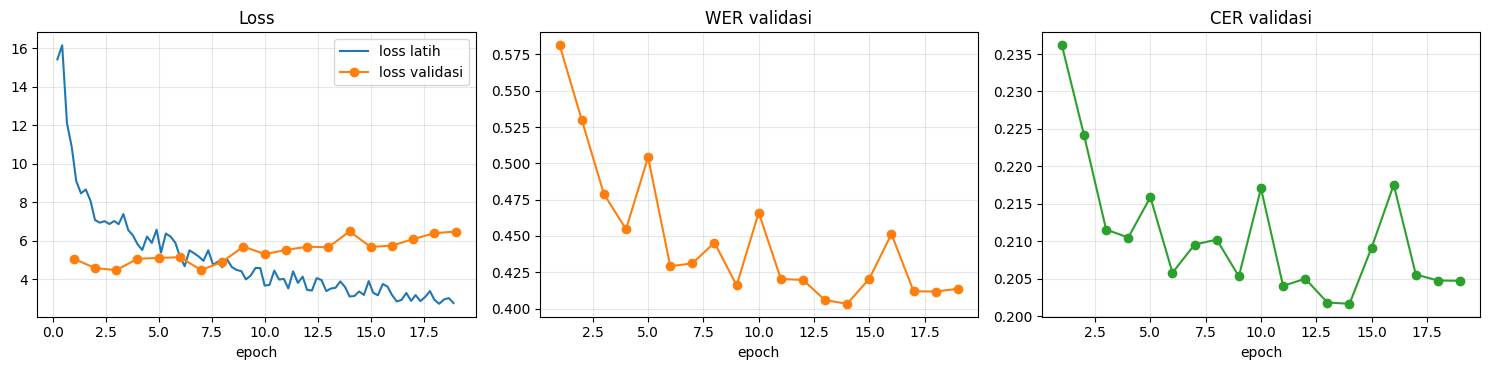

 epoch  eval_loss  eval_wer  eval_cer
   1.0     5.0568    0.5813    0.2362
   2.0     4.5785    0.5299    0.2242
   3.0     4.4681    0.4789    0.2116
   4.0     5.0565    0.4547    0.2105
   5.0     5.1038    0.5042    0.2159
   6.0     5.1398    0.4292    0.2058
   7.0     4.4752    0.4311    0.2096
   8.0     4.9023    0.4454    0.2102
   9.0     5.6927    0.4159    0.2053
  10.0     5.3029    0.4661    0.2171
  11.0     5.5138    0.4204    0.2041
  12.0     5.6877    0.4197    0.2050
  13.0     5.6562    0.4058    0.2018
  14.0     6.4831    0.4033    0.2017
  15.0     5.6728    0.4206    0.2092
  16.0     5.7433    0.4513    0.2176
  17.0     6.0807    0.4119    0.2056
  18.0     6.3889    0.4117    0.2048
  19.0     6.4740    0.4136    0.2047
checkpoint terpilih: /kaggle/working/asr_outputs/indonesian_nlp_finetuned/checkpoints/checkpoint-630 | epoch WER terbaik: 14.0 | epoch CER terbaik: 14.0
                model    wer    cer  wer_folded  cer_folded  e_word_accuracy  e_chars_p

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

uji kewajaran: model tersimpan konsisten (CER 8 ujaran 0.3070 vs 0.3070)


In [13]:
history = history_frame(trainer)
ev = history[history["eval_wer"].notna()]
fig = plot_history(history)
fig.savefig(os.path.join(RUN_DIR, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()
print(ev[["epoch", "eval_loss", "eval_wer", "eval_cer"]].round(4).to_string(index=False))
best_wer_epoch = float(ev.loc[ev.eval_wer.idxmin(), "epoch"])
best_cer_epoch = float(ev.loc[ev.eval_cer.idxmin(), "epoch"])
print("checkpoint terpilih:", trainer.state.best_model_checkpoint, "| epoch WER terbaik:", best_wer_epoch, "| epoch CER terbaik:", best_cer_epoch)

val_preds = transcribe_files(trainer.model, processor, val.abs_audio_path.tolist(), batch_size=4, device=DEVICE)
val_metrics = evaluate_predictions(val_refs, val_preds)

METRIC_COLUMNS = ["wer", "cer", "wer_folded", "cer_folded", "e_word_accuracy", "e_chars_predicted"]
val_table = pd.DataFrame([
    {"model": "baseline (zero-shot)", **{k: base_val[k] for k in METRIC_COLUMNS}},
    {"model": f"fine-tuned (epoch {best_wer_epoch:g})", **{k: val_metrics[k] for k in METRIC_COLUMNS}}])
print(val_table.round(4).to_string(index=False))
print(f"kata ber-é benar: {val_metrics['e_words_correct']}/{val_metrics['e_words_total']} | "
      f"huruf é diprediksi: {val_metrics['e_chars_predicted']} (referensi {val_metrics['e_chars_reference']})")

cfg_record = {"model_id": MODEL_ID, "model_revision": model_revision(MODEL_ID), "seed": SEED,
              "training": cfg["training"], "model_overrides": cfg["model"], "sweep": cfg["sweep"],
              "best_lr": BEST_LR, "sweep_results": sweep_results.to_dict("records"),
              "best_epoch_wer": best_wer_epoch, "best_epoch_cer": best_cer_epoch,
              "best_checkpoint": trainer.state.best_model_checkpoint, "vocab_extended_with": vocab_extended,
              "tokenizer": {k: v for k, v in audit.items() if k != "missing_target_chars"},
              "normalization_version": meta["normalization_version"], "decoding": "greedy CTC",
              "split": {"manifest_fingerprint": meta["manifest_fingerprint"], "seed": meta["seed"],
                        "train_speakers": meta["subsets"]["train"]["speakers"],
                        "val_speakers": meta["subsets"]["val"]["speakers"],
                        "test_speakers": meta["subsets"]["test"]["speakers"]},
              "n_train": len(train), "n_val": len(val), "env": env_info(), "resumed_from": checkpoint}
metrics = {"model_id": MODEL_ID, "split": "val", "epoch": best_wer_epoch, **val_metrics, "baseline": base_val}
save_artifacts(trainer, processor, RUN_DIR, cfg_record, val, val_preds, metrics, val_table)

del trainer
gc.collect()
torch.cuda.empty_cache()

final_model = Wav2Vec2ForCTC.from_pretrained(os.path.join(RUN_DIR, "model")).to(DEVICE)
final_processor = Wav2Vec2Processor.from_pretrained(os.path.join(RUN_DIR, "processor"))
check_paths = val.abs_audio_path.tolist()[:8]
reloaded_preds = transcribe_files(final_model, final_processor, check_paths, batch_size=4, device=DEVICE)
cer_memory = compute_error_rates(val_refs[:8], val_preds[:8])["cer"]
cer_saved = compute_error_rates(val_refs[:8], reloaded_preds)["cer"]
assert abs(cer_memory - cer_saved) < 0.02, f"model tersimpan berbeda: CER {cer_saved:.3f} vs {cer_memory:.3f}"
print(f"uji kewajaran: model tersimpan konsisten (CER 8 ujaran {cer_saved:.4f} vs {cer_memory:.4f})")

## K. Analisis kesalahan (validasi)
Bagian ini memuat tiga contoh pertama (urutan berkas, tanpa dipilih), lima ujaran terburuk, WER/CER per penutur, status penutur asli (indikator aksen dan dialek), kualitas rekaman (indikator derau), dan durasi, kata yang paling sering salah, serta kesalahan pada kata yang tidak ada di data latih. Perbedaan ejaan lisan dan tulisan terlihat pada daftar substitusi dan pada selisih metrik ketat terhadap *tanpa aksen*. Semua tabel disimpan di `RUN_DIR/analysis/`.

In [14]:
val_analysis = error_analysis(val, val_preds, train_vocab, "val", os.path.join(RUN_DIR, "analysis"))

== Tiga contoh pertama (val)
               file                                                                                            reference                                                                                           prediction   wer   cer
G04_S05_T01_001.WAV                                                     nami abdi mayla yaffa ludmilla tiasa disaur lala                                                    nami abdi maén layaka leuk mila biasa disaur lala 0.625 0.229
G04_S05_T01_002.WAV umur abdi dua puluh taun sareng ayeuna abdi mahasiswa jurusan teknik informatika di institut tekn... umur abdi dua puluh tahun sareng ayeuna abdi mahasiswa jorusan teknik informatika di institut tek... 0.125 0.018
G04_S05_T01_003.WAV                                          atanapi itb abdi parantos cicing di bandung ti saprak lahir                                           atanapi itb abdi parantos cicing di bandung ti saprak ahir 0.100 0.017

== Lima ujaran dengan CER tertingg

## L. Evaluasi data uji
Dilakukan **satu kali**, setelah model final ditetapkan dari validasi (aturan: WER validasi terendah), tidak ada keputusan yang diubah berdasarkan hasil ini. Baseline zero-shot dihitung pada himpunan yang sama untuk perbandingan.

In [15]:
test = load_split(DATASET_ROOT, "test")
assert set(test.speaker_id) == set(meta["subsets"]["test"]["speakers"])
assert set(test.speaker_id).isdisjoint(train.speaker_id) and set(test.speaker_id).isdisjoint(val.speaker_id)
assert (test.transcription_normalized.str.len() > 0).all()
for path in test.abs_audio_path:
    check_audio(path, cfg["sampling_rate"])

test_refs = test.transcription_normalized.tolist()
test_preds = transcribe_files(final_model, final_processor, test.abs_audio_path.tolist(), batch_size=4, device=DEVICE)
test_metrics = evaluate_predictions(test_refs, test_preds)
base_test_preds, base_test = zero_shot(test)

test_table = pd.DataFrame([
    {"model": "baseline (zero-shot)", **{k: base_test[k] for k in METRIC_COLUMNS}},
    {"model": f"fine-tuned (epoch {best_wer_epoch:g})", **{k: test_metrics[k] for k in METRIC_COLUMNS}}])
print(f"{len(test)} ujaran uji, penutur {sorted(test.speaker_id.unique())}")
print(test_table.round(4).to_string(index=False))
print(f"kata ber-é benar: {test_metrics['e_words_correct']}/{test_metrics['e_words_total']} | "
      f"huruf é diprediksi: {test_metrics['e_chars_predicted']} (referensi {test_metrics['e_chars_reference']})")

test_analysis = error_analysis(test, test_preds, train_vocab, "test", os.path.join(RUN_DIR, "analysis"))
test_table.to_csv(os.path.join(RUN_DIR, "test_comparison.csv"), index=False)
(Path(RUN_DIR) / "test_metrics.json").write_text(json.dumps(
    {"model_id": MODEL_ID, "split": "test", "epoch": best_wer_epoch, **test_metrics, "baseline": base_test},
    indent=2, default=str), encoding="utf-8")

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

327 ujaran uji, penutur ['G04_S07', 'G04_S11', 'S04', 'S09']
                model    wer    cer  wer_folded  cer_folded  e_word_accuracy  e_chars_predicted
 baseline (zero-shot) 0.6657 0.2296      0.6305      0.2181           0.0000                  0
fine-tuned (epoch 14) 0.4106 0.1473      0.3991      0.1442           0.7465                344
kata ber-é benar: 215/288 | huruf é diprediksi: 344 (referensi 313)
== Tiga contoh pertama (test)
               file                                                                                            reference                                                                                        prediction   wer   cer
G04_S07_T01_001.wav                   oke ee nami abdi mochamad ikhbar adiwinanggun tapi biasana abdi téh dipanggil ibay                   h nami abdi mohor manik bara dipi nangkon a tapi biasana abdi teh dipangil ibai 0.846 0.293
G04_S07_T01_002.wav ayeuna abdi nuju kuliah di itb ee jurusan sistem tekologi informasi ee 

1299

## M. Demo transkripsi
Mengubah audio bahasa daerah menjadi teks dengan model final. Isi `DEMO_AUDIO` dengan path berkas audio (WAV atau FLAC, stereo dan laju sampel lain dikonversi otomatis). Bila kosong, dipakai satu ujaran dari data uji beserta referensinya.

In [16]:
DEMO_AUDIO = None

demo_path = DEMO_AUDIO or test.abs_audio_path.iloc[0]
demo_wave = load_any_audio(demo_path, final_processor.feature_extractor.sampling_rate)
demo_text = transcribe_waves(final_model, final_processor, [demo_wave], batch_size=1, device=DEVICE)[0]
display(Audio(demo_wave, rate=final_processor.feature_extractor.sampling_rate))
print("audio     :", demo_path)
print("transkripsi:", demo_text)
if DEMO_AUDIO is None:
    print("referensi  :", test.transcription_normalized.iloc[0])

audio     : /kaggle/input/datasets/nathanieljr/if4071-sunda-speech-corpus-wav2vec-2-0/kaggle_export/audio/G04/S07/S07_T01_001.wav
transkripsi: h nami abdi mohor manik bara dipi nangkon a tapi biasana abdi teh dipangil ibai
referensi  : oke ee nami abdi mochamad ikhbar adiwinanggun tapi biasana abdi téh dipanggil ibay


## N. Ringkasan dan referensi
**Keterbatasan:** 
1. Hanya empat penutur validasi dan empat penutur uji, sehingga hasil peka terhadap penutur 
2. Uji learning rate singkat (5 epoch) dengan satu seed 
3. Dekode greedy tanpa model bahasa 
4. Status penutur asli tidak diketahui (`Unknown`) untuk sebagian rekaman 
5. Pembagian tidak diseimbangkan menurut gender, status penutur asli, maupun derau.

**Referensi:**
- Baevski, A., Zhou, H., Mohamed, A., Auli, M. (2020). *wav2vec 2.0: A Framework for Self-Supervised Learning of Speech Representations.* NeurIPS. arXiv:2006.11477.
- Graves, A., Fernández, S., Gomez, F., Schmidhuber, J. (2006). *Connectionist Temporal Classification: Labelling Unsegmented Sequence Data with Recurrent Neural Networks.* ICML.
- Checkpoint: `indonesian-nlp/wav2vec2-indonesian-javanese-sundanese`, https://huggingface.co/indonesian-nlp/wav2vec2-indonesian-javanese-sundanese (revisi tercatat di `training_config.json`).
- Resep pelatihan: model card dan notebook Cahya (`XLSR_Wav2Vec2_for_Indonesian_Fine_Tuning-Sundanese.ipynb` di repositori `cahya-wirawan/indonesian-speech-recognition`), melalui notebook 02.
- Pustaka: PyTorch (Paszke et al., 2019), Hugging Face Transformers (Wolf et al., 2020), `jiwer` (https://github.com/jitsi/jiwer), `soundfile` (https://github.com/bastibe/python-soundfile), SciPy, pandas, NumPy, dan versinya tercatat di `training_config.json`.
- Data: korpus suara bahasa Sunda Fase 1 (korpus kelompok dan G04), dataset Kaggle "IF4071 Sunda Speech Corpus Wav2Vec 2.0".

In [17]:
SUMMARY_COLUMNS = ["wer", "cer", "wer_folded", "cer_folded"]
summary = pd.DataFrame([
    {"himpunan": "validasi", "model": "baseline (zero-shot)", **{k: base_val[k] for k in SUMMARY_COLUMNS}},
    {"himpunan": "validasi", "model": "fine-tuned", **{k: val_metrics[k] for k in SUMMARY_COLUMNS}},
    {"himpunan": "uji", "model": "baseline (zero-shot)", **{k: base_test[k] for k in SUMMARY_COLUMNS}},
    {"himpunan": "uji", "model": "fine-tuned", **{k: test_metrics[k] for k in SUMMARY_COLUMNS}}])
summary.to_csv(os.path.join(RUN_DIR, "summary.csv"), index=False)
print(summary.round(4).to_string(index=False))

if CLEAN_CHECKPOINTS:
    shutil.rmtree(CKPT_DIR, ignore_errors=True)
for root, _, files in os.walk(RUN_DIR):
    print(root.replace(RUN_DIR, RUN_NAME), sorted(files))

himpunan                model    wer    cer  wer_folded  cer_folded
validasi baseline (zero-shot) 0.7097 0.2875      0.6730      0.2735
validasi           fine-tuned 0.4159 0.2041      0.4046      0.2003
     uji baseline (zero-shot) 0.6657 0.2296      0.6305      0.2181
     uji           fine-tuned 0.4106 0.1473      0.3991      0.1442
indonesian_nlp_finetuned ['summary.csv', 'sweep_results.csv', 'test_comparison.csv', 'test_metrics.json', 'training_config.json', 'training_curves.png', 'training_history.csv', 'validation_comparison.csv', 'validation_metrics.json', 'validation_predictions.csv']
indonesian_nlp_finetuned/model ['config.json', 'model.safetensors']
indonesian_nlp_finetuned/sweep []
indonesian_nlp_finetuned/sweep/lr_0.0001 []
indonesian_nlp_finetuned/sweep/lr_1e-05 []
indonesian_nlp_finetuned/sweep/lr_3e-05 []
indonesian_nlp_finetuned/sweep/lr_0.0003 []
indonesian_nlp_finetuned/analysis ['test_group_metrics.csv', 'test_per_utterance.csv', 'test_rare_words.csv', 'test_top_e